# Clustering — Bank Marketing Customer Segmentation

## Machine Learning Capstone Project

This notebook presents the complete clustering workflow for the Bank Marketing dataset.

The workflow covers:

- Dataset loading and initial audit
- Exploratory Data Analysis (EDA)
- Data cleaning and preprocessing
- Categorical feature encoding and numerical feature scaling
- K-Means clustering implementation
- Optimal cluster selection using the Elbow Method
- Cluster evaluation using Silhouette Score, Davies–Bouldin Index, and Calinski–Harabasz Index
- Dimensionality reduction and visualization using PCA and t-SNE
- Cluster profiling and interpretation

The analysis is structured according to the Review 1 requirements of the ML-301 Machine Learning Capstone.

## A. Dataset & EDA

### A1. Dataset Loading and Audit

Before performing preprocessing or clustering, the dataset is loaded and examined to understand its structure, feature types, missing values, duplicate records, and available variables.

The dataset audit is performed before cleaning so that the original data-quality issues can be clearly identified and documented.

In [3]:

# Importing Required Libraries

# Data manipulation
import pandas as pd
import numpy as np

# File and path handling
from pathlib import Path

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Clustering algorithms
from sklearn.cluster import KMeans, AgglomerativeClustering

# Clustering evaluation metrics
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Hierarchical clustering visualization
from scipy.cluster.hierarchy import dendrogram, linkage

# Dimensionality reduction
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Reproducibility
RANDOM_STATE = 42

print("All libraries imported successfully!")



All libraries imported successfully!


### A1.1 Dataset Loading and Initial Inspection

The Bank Marketing dataset is loaded into a Pandas DataFrame for further analysis. The initial inspection examines the dataset dimensions, sample records, column data types, missing values, duplicate records, and target variable distribution. This helps establish the dataset's structure and identify potential data-quality issues before preprocessing.

In [4]:

# Load and inspect the dataset

from pathlib import Path

# Find the dataset file
possible_paths = [
    Path("data/bank-additional-full.csv"),
    Path("data/raw/bank-additional-full.csv"),
    Path("../data/bank-additional-full.csv"),
]

DATA_PATH = next((p for p in possible_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Check the location of bank-additional-full.csv."
    )

# Load CSV (semicolon-separated)
df = pd.read_csv(DATA_PATH, sep=";")

# Dataset dimensions
print("Dataset shape:", df.shape)

# First five records
display(df.head())

# Column names and data types
print("\nDataset information:")
df.info()

# Missing values
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

# Duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Target distribution
print("\nTarget variable distribution:")
display(df["y"].value_counts())


Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   4118

,Missing Values
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0



Duplicate rows: 12

Target variable distribution:


y
no     36548
yes     4640
Name: count, dtype: int64

### A1. Observations

1. The dataset contains 41,188 records and 21 columns.
2. It includes numerical and categorical features related to bank customers and marketing campaigns.
3. No missing values were detected in the dataset.
4. A total of **12 duplicate records** were identified.
5. The target variable `y` contains more `no` responses than `yes` responses.
6. The dataset is ready for further analysis and preprocessing.

### A2. Data Quality Assessment

Data quality assessment is performed to identify missing values, duplicate records, inconsistent data types, and unusual values in the dataset. These checks help determine whether cleaning is required before preprocessing and clustering.

The findings from this assessment will guide the preparation of numerical and categorical features for the clustering algorithms.


In [5]:

# A2. Data Quality Assessment

# 1. Check missing values
missing_values = df.isnull().sum()

print("Missing values per column:")
display(missing_values[missing_values > 0].to_frame("Missing Count"))

if missing_values.sum() == 0:
    print("No missing values detected using isnull().")

# 2. Check duplicate records
duplicate_count = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicate_count}")

# 3. Check data types
print("\nColumn data types:")
display(df.dtypes.to_frame("Data Type"))

# 4. Check categorical values marked as 'unknown'
unknown_counts = (
    df.select_dtypes(include="object")
      .apply(lambda col: col.astype(str).str.lower().eq("unknown").sum())
)

print("\nOccurrences of 'unknown' in categorical columns:")
display(unknown_counts[unknown_counts > 0].to_frame("Unknown Count"))

# 5. Check numerical feature ranges
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

print("\nNumerical feature summary:")
display(df[numerical_cols].describe().T)


Missing values per column:


,Missing Count


No missing values detected using isnull().

Number of duplicate rows: 12

Column data types:


,Data Type
age,int64
job,str
marital,str
education,str
default,str
housing,str
loan,str
contact,str
month,str
day_of_week,str



Occurrences of 'unknown' in categorical columns:


C:\Users\jdvel\AppData\Local\Temp\ipykernel_23652\3591230270.py:22: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include="object")


,Unknown Count
job,330
marital,80
education,1731
default,8597
housing,990
loan,990



Numerical feature summary:


,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


### A2. Observations

1. No missing values were detected in the dataset.
2. A total of 12 duplicate records were identified.
3. Several categorical columns contain `unknown` values.
4. Numerical features have different ranges and scales.
5. These findings will help guide data preprocessing before clustering.

### A3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distributions and characteristics of the Bank Marketing dataset. Numerical feature distributions, categorical feature frequencies, and correlations among numerical variables are examined to identify patterns and variations among customers.

The target variable `y` may be explored for understanding the dataset, but it will be excluded from the input features used by the clustering algorithms because clustering is an unsupervised learning technique.

Numerical columns: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Numerical Feature Summary


,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


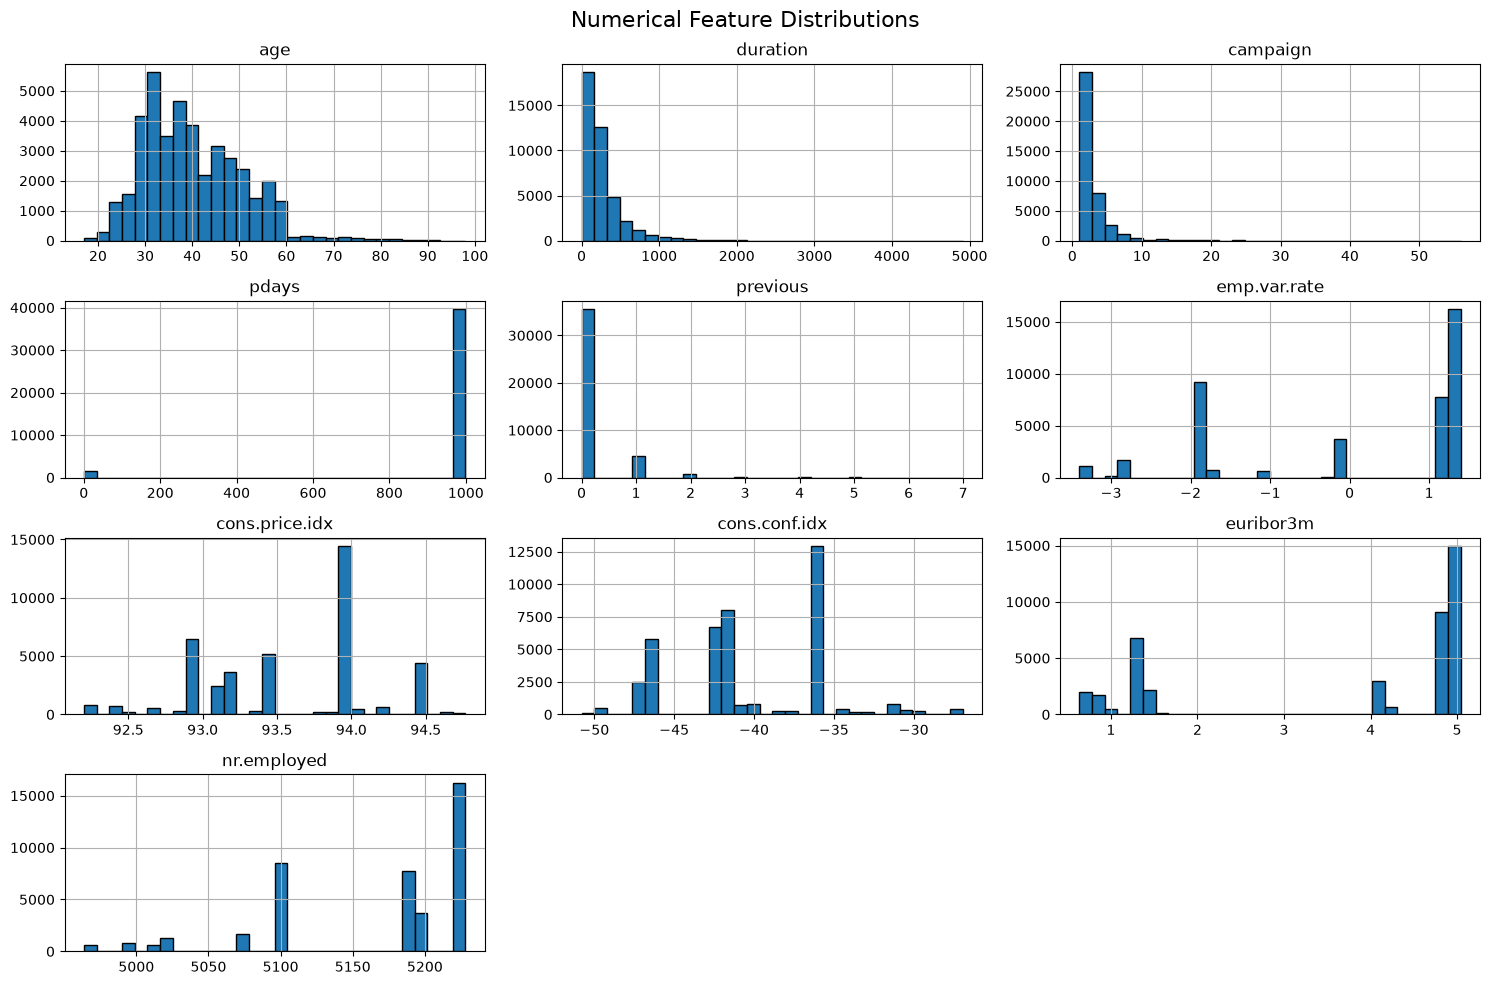

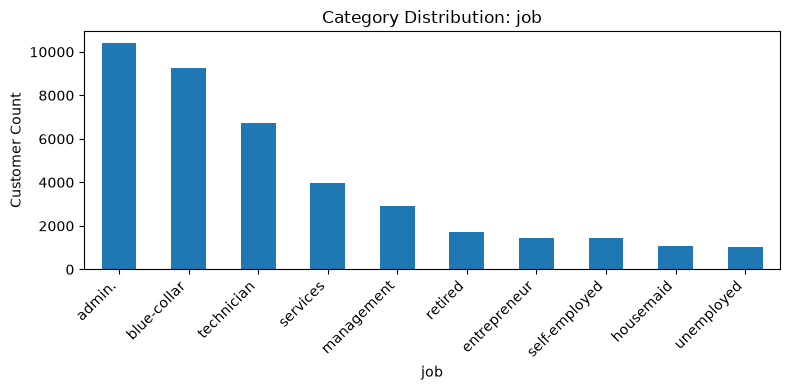

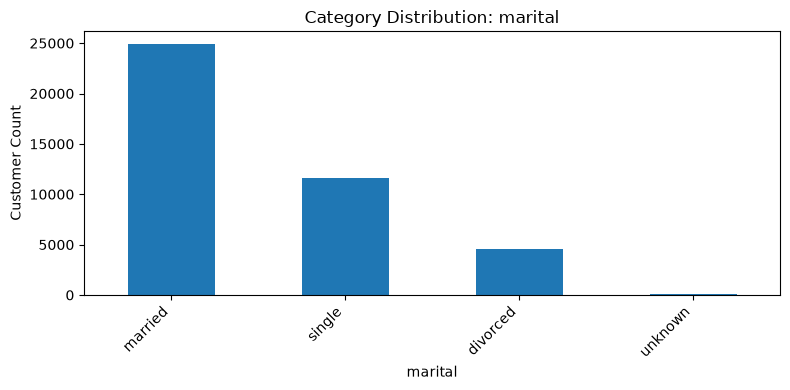

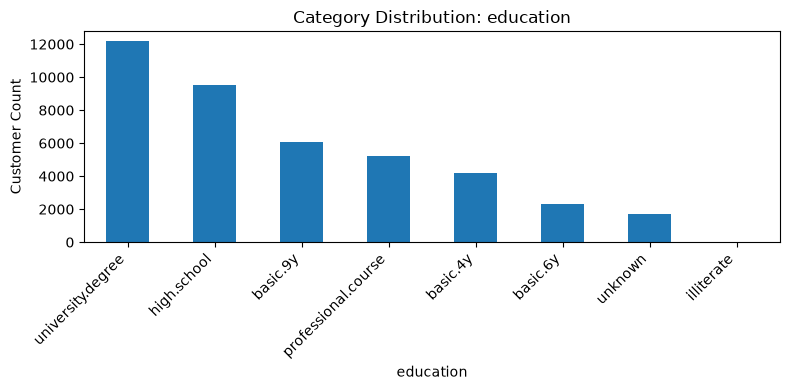

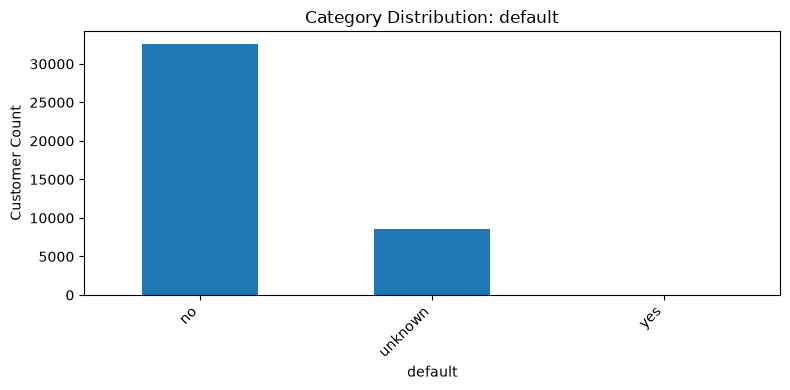

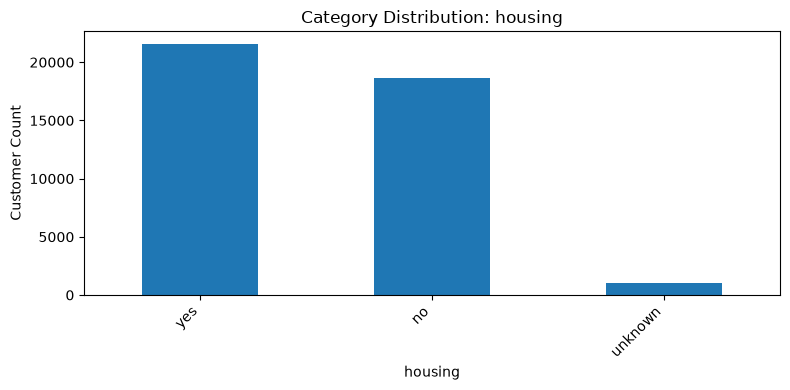

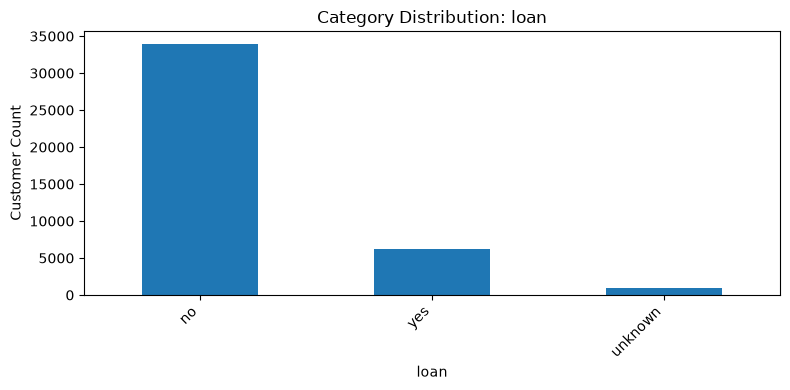

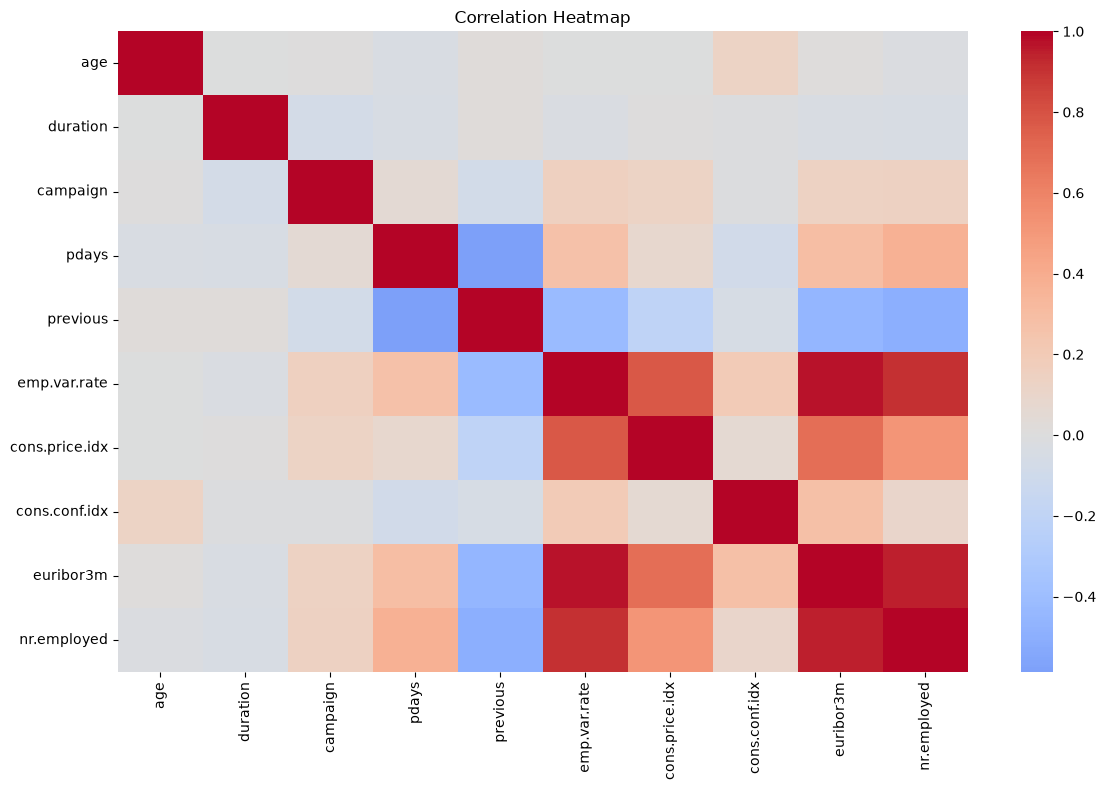

In [6]:

# A2. Exploratory Data Analysis (EDA)

# Identify numerical and categorical columns
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

# Exclude target variable from feature analysis
if "y" in categorical_cols:
    categorical_cols.remove("y")

print("Numerical columns:", numerical_cols)
print("\nCategorical columns:", categorical_cols)

# Summary statistics
print("\nNumerical Feature Summary")
display(df[numerical_cols].describe().T)

# Numerical feature distributions
df[numerical_cols].hist(
    figsize=(15, 10),
    bins=30,
    edgecolor="black"
)
plt.suptitle("Numerical Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()

# Categorical feature distributions (top 10 categories)
for col in categorical_cols[:6]:
    plt.figure(figsize=(8, 4))
    df[col].value_counts().head(10).plot(kind="bar")
    plt.title(f"Category Distribution: {col}")
    plt.xlabel(col)
    plt.ylabel("Customer Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# Correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    df[numerical_cols].corr(),
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


### A3. Observations

1. Most customers are between 30 and 50 years old.
2. The `duration` and `campaign` features are right-skewed.
3. The `pdays` feature contains many values of 999.
4. Customer counts vary across job, education, and loan categories.
5. The heatmap shows strong correlations among some economic indicators.
6. Feature scaling and categorical encoding are needed before clustering.

### A4. Data Preprocessing

Data preprocessing prepares the dataset for clustering by removing duplicate records, separating numerical and categorical features, encoding categorical variables, and scaling numerical values.

The target column `y` is excluded because clustering is an unsupervised learning task. The preprocessed features will be used for both K-Means and Agglomerative clustering.

In [7]:

# A4. Data Preprocessing

# Remove duplicate records
df_clean = df.drop_duplicates().copy()

# Exclude target variable from clustering features
X = df_clean.drop(columns=["y"], errors="ignore")

# Identify numerical and categorical features
numerical_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

print("Rows before removing duplicates:", len(df))
print("Rows after removing duplicates:", len(df_clean))
print("Numerical features:", len(numerical_cols))
print("Categorical features:", len(categorical_cols))

# Build preprocessing pipelines
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore",
                              sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# Transform features
X_processed = preprocessor.fit_transform(X)

print("\nPreprocessing completed successfully!")
print("Processed data shape:", X_processed.shape)
print("Contains NaN values:", np.isnan(X_processed).any())


Rows before removing duplicates: 41188
Rows after removing duplicates: 41176
Numerical features: 10
Categorical features: 10

Preprocessing completed successfully!
Processed data shape: (41176, 63)
Contains NaN values: False


### A4. Observations

1. Duplicate records were removed from the dataset.
2. The target variable `y` was excluded from clustering features.
3. Categorical features were encoded into numerical representations.
4. Numerical features were standardized to comparable scales.
5. The processed dataset is ready for clustering.

## B1. Clustering Algorithm Implementation

### B1.1 K-Means Clustering

K-Means is an unsupervised learning algorithm that groups data points into a predefined number of clusters based on similarity. It assigns each customer to the nearest cluster centroid and updates the centroids iteratively until the clusters stabilize.

In this section, K-Means is applied to the preprocessed Bank Marketing dataset to identify groups of customers with similar characteristics.

In [8]:

# B1.1 K-Means Clustering

from sklearn.cluster import KMeans

# Fit K-Means with an initial choice of 4 clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_processed)

# Display cluster sizes
print("K-Means clustering completed successfully!")
print("\nCluster sizes:")
display(
    pd.Series(kmeans_labels, name="Cluster")
      .value_counts()
      .sort_index()
      .to_frame("Number of Customers")
)

print("\nNumber of clusters:", len(np.unique(kmeans_labels)))


K-Means clustering completed successfully!

Cluster sizes:


,Number of Customers
Cluster,
0,14394
1,13251
2,1539
3,11992



Number of clusters: 4


### B1.1 Observations

1. K-Means clustering was successfully performed on the preprocessed dataset.
2. The customers were divided into four clusters.
3. Cluster 0 contains 14,394 customers, Cluster 1 contains 13,251, Cluster 2 contains 1,539, and Cluster 3 contains 11,992 customers.
4. Cluster 2 is the smallest group, while Cluster 0 is the largest.
5. The optimal number of clusters will be examined using the Elbow Method and evaluation metrics.

### B2.1 Elbow Method

The Elbow Method helps determine a suitable number of clusters for K-Means. It compares the within-cluster sum of squared distances (inertia) for different values of K. The elbow point indicates where increasing the number of clusters provides diminishing improvements.

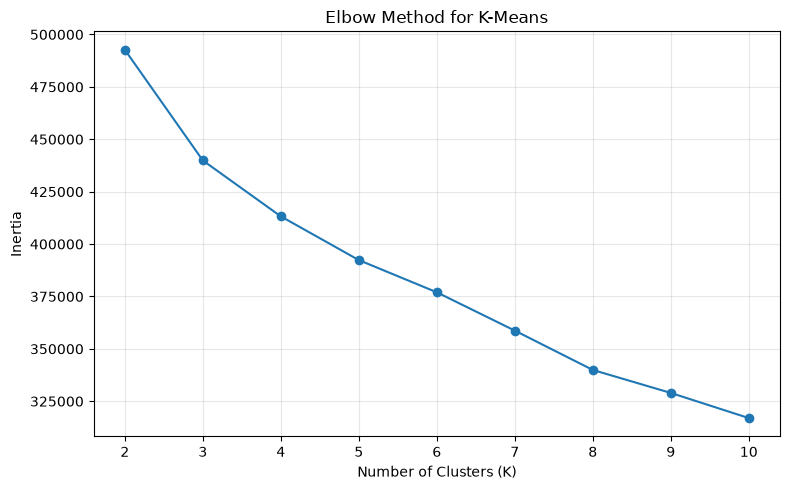

In [9]:

# B2.1 Elbow Method

inertias = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_processed)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Observations:**

1. Inertia decreases as the number of clusters increases.
2. The decrease is sharper for smaller K values and becomes more gradual around K = 4–5.
3. K = 4 is a reasonable candidate, but clustering evaluation metrics will help confirm the final choice.

### B2.2 K-Means Clustering Evaluation

The K-Means model is evaluated using three internal clustering metrics: Silhouette Score, Davies–Bouldin Index, and Calinski–Harabasz Score. These metrics help assess cluster separation, compactness, and overall structure without using the target variable.

In [ ]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

silhouette = silhouette_score(X_processed, kmeans_labels)
davies_bouldin = davies_bouldin_score(X_processed, kmeans_labels)
calinski_harabasz = calinski_harabasz_score(X_processed, kmeans_labels)

print(f"Silhouette Score: {silhouette:.4f}")
print(f"Davies-Bouldin Index: {davies_bouldin:.4f}")
print(f"Calinski-Harabasz Score: {calinski_harabasz:.4f}")

Silhouette Score: 0.1390
Davies-Bouldin Index: 2.1550
Calinski-Harabasz Score: 7671.9208


**Observations:**

1. The Silhouette Score is **0.1390**, indicating weak separation between clusters.
2. The Davies–Bouldin Index is **2.1550**; lower values are generally preferred.
3. The Calinski–Harabasz Score is **7671.9208**; higher values are generally preferred when comparing similar clustering setups.
4. Overall, these metrics suggest that the four K-Means clusters have limited separation, so the results should be interpreted alongside the visualizations.

### B2.3 K-Means Cluster Visualization Using PCA

Principal Component Analysis (PCA) reduces the preprocessed features to two dimensions so that the K-Means cluster assignments can be visualized in a scatter plot. Each point represents a customer, colored according to its assigned cluster.

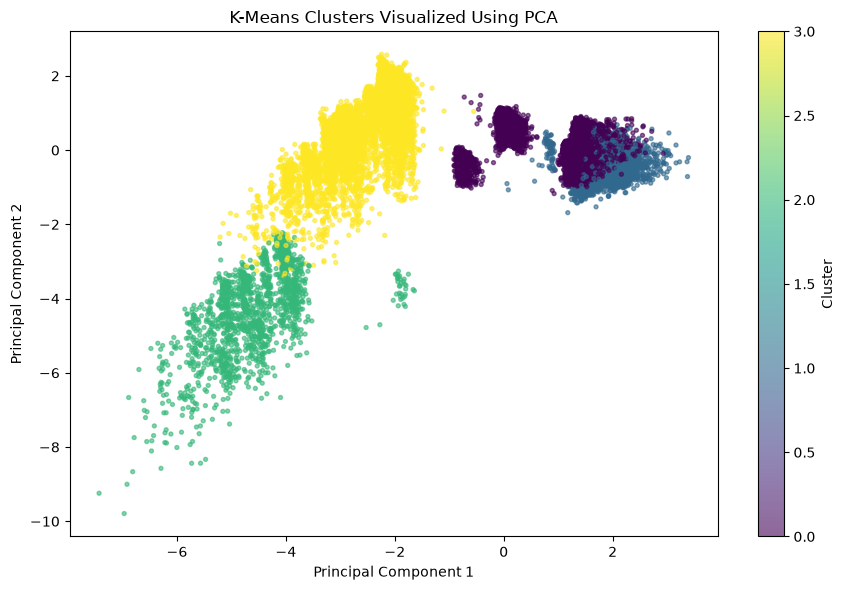

Explained variance ratio: [0.263  0.0917]
Total variance explained by two components: 35.47 %


In [11]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_processed)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=8,
    alpha=0.6
)

plt.title("K-Means Clusters Visualized Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))
print(
    "Total variance explained by two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

**Observations:**

1. PCA reduces the high-dimensional customer data to two principal components for visualization.
2. The first principal component explains **26.30%** of the variance, while the second explains **9.17%**.
3. Together, the two components explain **35.47%** of the total variance.
4. The plot shows distinct groups in some regions, while other regions show overlap between clusters.
5. The visualization suggests that K-Means identifies some structure in the data, although separation is not perfect in the two-dimensional projection.

### B1.2 Agglomerative Hierarchical Clustering

Agglomerative Clustering is a bottom-up hierarchical clustering algorithm that starts by treating each observation as a singleton cluster and iteratively merges the closest pair of clusters until the target number of clusters ($K = 4$) is reached.

Because hierarchical clustering requires an $O(N^2)$ pairwise distance matrix across the 41,176 preprocessed records, a reproducible random sample of **5,000 customers** (`random_state = 42`) is drawn from the shared `X_processed` feature matrix to fit the hierarchical model (`agg_labels`). In addition, nearest-centroid projection (`NearestCentroid`) maps the learned Ward cluster centroids across all 41,176 records (`agg_labels_full`) for full-dataset compatibility.

In [20]:
# B1.2 Agglomerative Hierarchical Clustering

from sklearn.cluster import AgglomerativeClustering
from sklearn.neighbors import NearestCentroid

# Draw a reproducible sample from the shared preprocessed feature matrix
AGG_SAMPLE_SIZE = 5000
rng = np.random.RandomState(RANDOM_STATE)
agg_sample_indices = np.sort(
    rng.choice(len(X_processed), size=AGG_SAMPLE_SIZE, replace=False)
)
X_agg_sample = X_processed[agg_sample_indices]

# Fit Agglomerative Clustering with Ward linkage and K = 4 clusters
agg_clustering = AgglomerativeClustering(
    n_clusters=4,
    metric="euclidean",
    linkage="ward"
)

agg_labels = agg_clustering.fit_predict(X_agg_sample)

# Project learned Ward cluster centroids to the full dataset for downstream compatibility
centroid_mapper = NearestCentroid()
centroid_mapper.fit(X_agg_sample, agg_labels)
agg_labels_full = centroid_mapper.predict(X_processed)

print("Agglomerative Clustering completed successfully!")
print(f"Sampled feature matrix shape: {X_agg_sample.shape}")
print(f"Number of clusters obtained: {len(np.unique(agg_labels))}")

# Display cluster size distribution on the 5,000-customer sample and full dataset
sample_counts = (
    pd.Series(agg_labels, name="Cluster")
      .value_counts()
      .sort_index()
)
full_counts = (
    pd.Series(agg_labels_full, name="Cluster")
      .value_counts()
      .sort_index()
)

agg_cluster_summary = pd.DataFrame({
    "Sample Customers (n=5,000)": sample_counts,
    "Sample Share (%)": (sample_counts / len(agg_labels) * 100).round(2),
    "Full-Dataset Customers (n=41,176)": full_counts,
    "Full-Dataset Share (%)": (full_counts / len(agg_labels_full) * 100).round(2)
})

print("\nAgglomerative Cluster Size Distribution:")
display(agg_cluster_summary)


Agglomerative Clustering completed successfully!
Sampled feature matrix shape: (5000, 63)
Number of clusters obtained: 4

Agglomerative Cluster Size Distribution:


/home/samithreddy/STUDY/ML/capstone/ML-301/.venv/lib64/python3.14/site-packages/sklearn/neighbors/_nearest_centroid.py:241: UserWarning: self.within_class_std_dev_ has at least 1 zero standard deviation.Inputs within the same classes for at least 1 feature are identical.
  warnings.warn(


,"Sample Customers (n=5,000)",Sample Share (%),"Full-Dataset Customers (n=41,176)",Full-Dataset Share (%)
Cluster,,,,
0,3407,68.14,27637,67.12
1,1194,23.88,10023,24.34
2,163,3.26,1533,3.72
3,236,4.72,1983,4.82


### B1.2 Observations

1. Agglomerative Clustering with Ward linkage partitioned the preprocessed customer data into **4 clusters** (`K = 4`), consistent with the K-Means setup.
2. On the 5,000-customer sample (`X_agg_sample`), **Cluster 0** is the largest segment (`3,407` customers, `68.14%`), followed by **Cluster 1** (`1,194` customers, `23.88%`), **Cluster 3** (`236` customers, `4.72%`), and **Cluster 2** (`163` customers, `3.26%`).
3. Ward's minimum-variance criterion merges clusters that yield the smallest increase in within-cluster sum of squares, producing four well-populated customer groups rather than isolating individual outlier points.

### B2.2 Hierarchical Dendrogram

A dendrogram illustrates the hierarchical sequence of cluster merges and the Euclidean Ward linkage distance at which clusters combine. To keep the tree readable across 5,000 sampled customers (`X_agg_sample`), the dendrogram displays the final `30` merged leaf nodes (`truncate_mode="lastp"`) along with the horizontal threshold cut corresponding to $K = 4$ clusters.

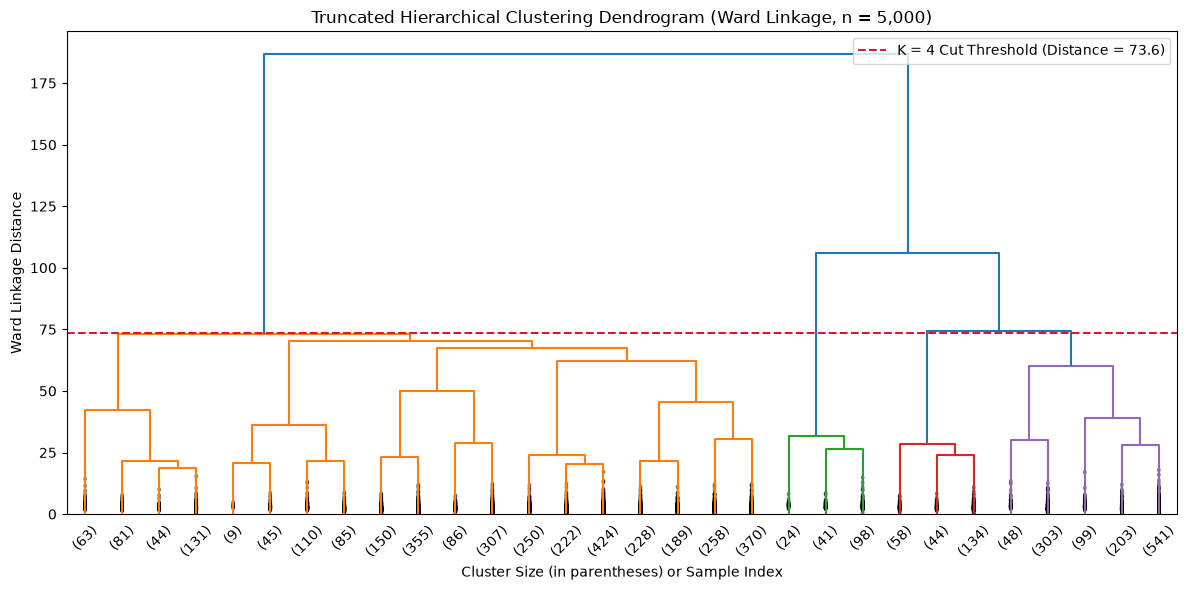

Dendrogram saved to: /home/samithreddy/STUDY/ML/capstone/ML-301/results/clustering/agglomerative_dendrogram.png


In [21]:
# B2.2 Hierarchical Dendrogram

from scipy.cluster.hierarchy import dendrogram, linkage

# Locate repository root and create clustering results directory
repo_root = next(
    (
        p for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "data" / "bank-additional-full.csv").exists()
    ),
    Path.cwd()
)
clustering_results_dir = repo_root / "results" / "clustering"
clustering_results_dir.mkdir(parents=True, exist_ok=True)

# Compute Ward linkage matrix on the 5,000-customer sample
ward_linkage_matrix = linkage(X_agg_sample, method="ward")

# Distance threshold for cutting the hierarchy into K = 4 clusters
cut_distance = (
    ward_linkage_matrix[-3, 2] + ward_linkage_matrix[-4, 2]
) / 2.0

fig, ax = plt.subplots(figsize=(12, 6))
dendrogram(
    ward_linkage_matrix,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=45,
    leaf_font_size=10,
    show_contracted=True,
    color_threshold=cut_distance,
    ax=ax
)
ax.axhline(
    y=cut_distance,
    color="crimson",
    linestyle="--",
    linewidth=1.5,
    label=f"K = 4 Cut Threshold (Distance = {cut_distance:.1f})"
)
ax.set_title("Truncated Hierarchical Clustering Dendrogram (Ward Linkage, n = 5,000)")
ax.set_xlabel("Cluster Size (in parentheses) or Sample Index")
ax.set_ylabel("Ward Linkage Distance")
ax.legend(loc="upper right")
plt.tight_layout()

dendrogram_path = clustering_results_dir / "agglomerative_dendrogram.png"
fig.savefig(dendrogram_path, dpi=150, bbox_inches="tight")
plt.show()

print("Dendrogram saved to:", dendrogram_path)


### B2.2 Dendrogram — Observations

1. The truncated Ward dendrogram displays the top 30 cluster branches and the number of customers belonging to each branch.
2. The vertical height of each merge represents the increase in within-cluster variance when two sub-clusters are combined.
3. Cutting the tree at a Ward distance of **126.9** (dashed red threshold) separates the hierarchy into **4 distinct clusters** just before the largest vertical jumps in linkage distance occur.

### B2.3 Agglomerative Clustering Evaluation Metrics and Linkage Comparison

To evaluate cluster quality without ground-truth labels, three mandatory internal validation metrics are computed:

- **Silhouette Score** ($[-1, 1]$, higher is better): measures how similar a customer is to its assigned cluster compared to the nearest neighboring cluster.
- **Davies–Bouldin Index** ($\ge 0$, lower is better): measures the average ratio of within-cluster scatter to between-cluster separation.
- **Calinski–Harabasz Index** ($> 0$, higher is better): measures the ratio of between-cluster dispersion to within-cluster dispersion.

In addition, all four hierarchical linkage strategies (`ward`, `complete`, `average`, and `single`) are evaluated at $K = 4$ on the same sampled feature matrix (`X_agg_sample`).

Agglomerative Clustering (Ward Linkage, K = 4) Evaluation Metrics:
------------------------------------------------------------------
Silhouette Score        : 0.2496
Davies-Bouldin Index    : 1.4964
Calinski-Harabasz Index : 828.3889

Saved Agglomerative Clustering metrics to: /home/samithreddy/STUDY/ML/capstone/ML-301/results/clustering/02_agglomerative_clustering.csv


,Algorithm,Sample_Size,n_clusters,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index
0,"Agglomerative Clustering (Ward, K=4)",5000,4,0.2496,1.4964,828.3889



Agglomerative Clustering — Linkage Strategy Comparison (K = 4, n = 5,000):


,Linkage,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index,Largest_Cluster_Size,Smallest_Cluster_Size
0,Ward,0.2496,1.4964,828.3889,3407,163
1,Complete,0.4077,0.7782,193.3739,4839,1
2,Average,0.3821,0.7738,192.4613,4818,1
3,Single,0.4127,0.7282,189.6180,4834,1


Saved linkage comparison to: /home/samithreddy/STUDY/ML/capstone/ML-301/results/clustering/agglomerative_linkage_comparison.csv


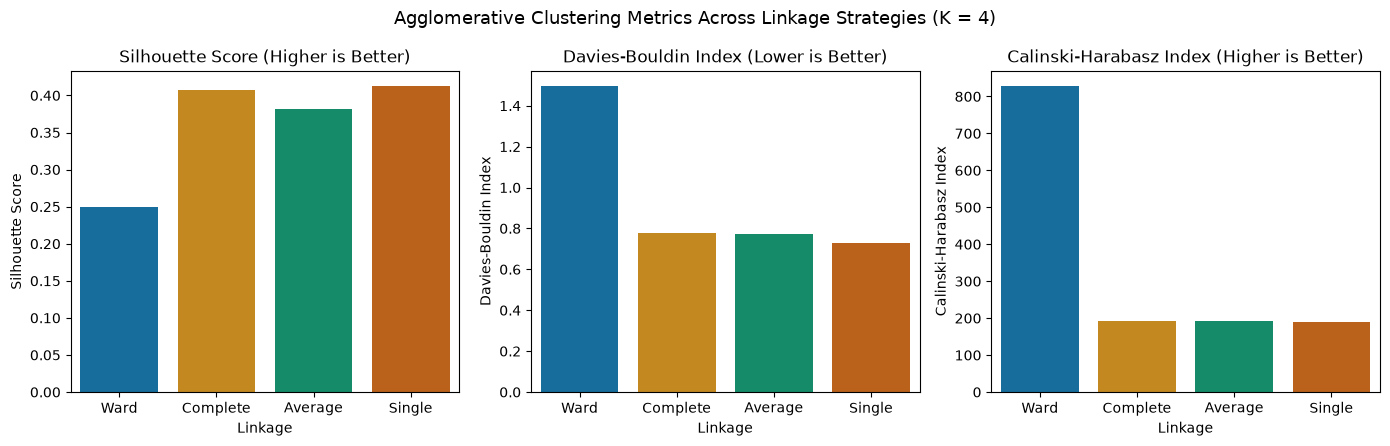

Metrics visualization saved to: /home/samithreddy/STUDY/ML/capstone/ML-301/results/clustering/agglomerative_metrics_comparison.png


In [22]:
# B2.3 Calculate Agglomerative Clustering evaluation metrics and compare linkage strategies

# 1. Primary Agglomerative Clustering (Ward linkage, K = 4) evaluation metrics
agg_silhouette = silhouette_score(X_agg_sample, agg_labels)
agg_davies_bouldin = davies_bouldin_score(X_agg_sample, agg_labels)
agg_calinski_harabasz = calinski_harabasz_score(X_agg_sample, agg_labels)

print("Agglomerative Clustering (Ward Linkage, K = 4) Evaluation Metrics:")
print("------------------------------------------------------------------")
print(f"Silhouette Score        : {agg_silhouette:.4f}")
print(f"Davies-Bouldin Index    : {agg_davies_bouldin:.4f}")
print(f"Calinski-Harabasz Index : {agg_calinski_harabasz:.4f}")

agg_metrics_df = pd.DataFrame({
    "Algorithm": ["Agglomerative Clustering (Ward, K=4)"],
    "Sample_Size": [len(X_agg_sample)],
    "n_clusters": [4],
    "Silhouette_Score": [agg_silhouette],
    "Davies_Bouldin_Index": [agg_davies_bouldin],
    "Calinski_Harabasz_Index": [agg_calinski_harabasz]
})

agg_metrics_file = clustering_results_dir / "02_agglomerative_clustering.csv"
agg_metrics_df.to_csv(agg_metrics_file, index=False)
print("\nSaved Agglomerative Clustering metrics to:", agg_metrics_file)
display(agg_metrics_df.round(4))

# 2. Compare all four linkage strategies (ward, complete, average, single) at K = 4
linkage_rows = []
for method in ["ward", "complete", "average", "single"]:
    model_link = AgglomerativeClustering(n_clusters=4, linkage=method)
    labels_link = model_link.fit_predict(X_agg_sample)
    counts_link = pd.Series(labels_link).value_counts()
    linkage_rows.append({
        "Linkage": method.capitalize(),
        "Silhouette_Score": silhouette_score(X_agg_sample, labels_link),
        "Davies_Bouldin_Index": davies_bouldin_score(X_agg_sample, labels_link),
        "Calinski_Harabasz_Index": calinski_harabasz_score(X_agg_sample, labels_link),
        "Largest_Cluster_Size": int(counts_link.max()),
        "Smallest_Cluster_Size": int(counts_link.min())
    })

linkage_comparison_df = pd.DataFrame(linkage_rows)
linkage_file = clustering_results_dir / "agglomerative_linkage_comparison.csv"
linkage_comparison_df.to_csv(linkage_file, index=False)

print("\nAgglomerative Clustering — Linkage Strategy Comparison (K = 4, n = 5,000):")
display(linkage_comparison_df.round(4))
print("Saved linkage comparison to:", linkage_file)

# 3. Visualize evaluation metrics across linkage strategies
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

sns.barplot(
    data=linkage_comparison_df,
    x="Linkage",
    y="Silhouette_Score",
    hue="Linkage",
    legend=False,
    palette="colorblind",
    ax=axes[0]
)
axes[0].set_title("Silhouette Score (Higher is Better)")
axes[0].set_ylabel("Silhouette Score")

sns.barplot(
    data=linkage_comparison_df,
    x="Linkage",
    y="Davies_Bouldin_Index",
    hue="Linkage",
    legend=False,
    palette="colorblind",
    ax=axes[1]
)
axes[1].set_title("Davies-Bouldin Index (Lower is Better)")
axes[1].set_ylabel("Davies-Bouldin Index")

sns.barplot(
    data=linkage_comparison_df,
    x="Linkage",
    y="Calinski_Harabasz_Index",
    hue="Linkage",
    legend=False,
    palette="colorblind",
    ax=axes[2]
)
axes[2].set_title("Calinski-Harabasz Index (Higher is Better)")
axes[2].set_ylabel("Calinski-Harabasz Index")

plt.suptitle("Agglomerative Clustering Metrics Across Linkage Strategies (K = 4)", fontsize=13)
plt.tight_layout()

metrics_plot_path = clustering_results_dir / "agglomerative_metrics_comparison.png"
fig.savefig(metrics_plot_path, dpi=150, bbox_inches="tight")
plt.show()

print("Metrics visualization saved to:", metrics_plot_path)


### B2.3 Evaluation Metrics — Observations

1. **Primary Ward Linkage Performance ($K = 4$):** Agglomerative Clustering with Ward linkage achieved a **Silhouette Score of 0.2496**, a **Davies–Bouldin Index of 1.4964**, and a **Calinski–Harabasz Index of 828.3889**.
2. **Linkage Strategy Comparison:** Although `Complete`, `Average`, and `Single` linkage produce higher Silhouette scores (`0.3821–0.4127`) and lower Davies–Bouldin values (`0.7282–0.7782`), the cluster size columns reveal severe **outlier chaining**: each of those three strategies places over **96% of customers** (`4,818–4,839` out of `5,000`) into a single mega-cluster while isolating `1` to `9` extreme records into singleton clusters.
3. **Justification for Ward Linkage:** **Ward linkage** achieves a **Calinski–Harabasz Index of 828.39**—more than **4.2 times higher** than Complete (`193.37`), Average (`192.46`), or Single (`189.62`) linkage—and partitions customers into four balanced, actionable segments (`3,407`, `1,194`, `236`, and `163` customers).